# Notebook 1 — DF20-Mini → CLIP Embeddings

**One-time preprocessing.** Runs CLIP ViT-B/32 over every DF20-Mini image, assigns integer species IDs, carves out a fixed test set, and saves everything for downstream active-learning experiments.

## Problem framing

**Fine-grained image classification**: ~182 mushroom species across 6 genera (Russula, Boletus, Amanita, Clitocybe, Agaricus, Mycena). The dataset has a heavy long-tailed class distribution — most common species has >1000 images, rarest have 30ish. This is the setting where AL strategies should differentiate from random sampling.

## Outputs
- `artifacts/df20m_embeddings.npy` — `(N, 512)` float32, L2-normalized CLIP features
- `artifacts/df20m_metadata.parquet` — per-image rows: `image_path, species, species_id, genus, split, embedding_idx`
- `artifacts/species_info.parquet` — per-species table: `species, species_id, genus, n_images`
- `artifacts/df20m_summary.json` — reproducibility snapshot

## Runtime
M4 16GB with MPS backend: roughly 5–15 minutes for ~29k images at batch_size=64.

## Prerequisites
```bash
pip install torch torchvision open_clip_torch pandas pyarrow scikit-learn tqdm matplotlib
# DF20-Mini images extracted to: data/DF20M/
# DF20-Mini metadata CSV at:      data/DF20M-metadata.csv
```


In [1]:
# ==================== IMPORTS ====================
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

import open_clip

/Users/lucilu/miniconda3/envs/mushroom-project/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [21]:
# ==================== CONFIG ====================
DATA_DIR       = Path('data/DF20M')                     # folder with all .jpg files
METADATA_DIR   = Path('data/DF20M-metadata')            # contains the two split CSVs below
METADATA_TRAIN = METADATA_DIR / 'DF20M-train_metadata_PROD.csv'
METADATA_TEST  = METADATA_DIR / 'DF20M-public_test_metadata_PROD.csv'
OUTPUT_DIR     = Path('artifacts')
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

CLIP_MODEL_NAME = 'ViT-B-32'
CLIP_PRETRAINED = 'openai'
BATCH_SIZE      = 64
NUM_WORKERS     = 0
RANDOM_STATE    = 42

if torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.cuda.is_available():
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')
print(f"Using device: {DEVICE}")

Using device: mps


## Step 1 — Load Official Train/Test Metadata

DF20-Mini ships with **two metadata CSVs**:
- `DF20M-train_metadata_PROD.csv` — training observations
- `DF20M-public_test_metadata_PROD.csv` — held-out test observations

The official split is based on ObservationID: images from the same observation never appear in both splits. We use it as-is — both for reproducibility (results compare to other DF20-Mini papers) and to avoid data leakage.

Column names may shift between DF20 and DF24 versions — we inspect first, then adapt.

In [4]:
meta_train = pd.read_csv(METADATA_TRAIN)
meta_test  = pd.read_csv(METADATA_TEST)

meta_train['split'] = 'train'
meta_test['split']  = 'test'

print(f"Train rows: {len(meta_train):,}")
print(f"Test rows:  {len(meta_test):,}")
print(f"\nTrain columns: {meta_train.columns.tolist()}")
print(f"Test  columns: {meta_test.columns.tolist()}")
print(f"\nColumn sets equal: {set(meta_train.columns) == set(meta_test.columns)}")
meta_train.head(2)

Train rows: 32,753
Test rows:  3,640

Train columns: ['gbifID', 'eventDate', 'year', 'month', 'day', 'countryCode', 'locality', 'taxonID', 'scientificName', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'specificEpithet', 'infraspecificEpithet', 'taxonRank', 'species', 'level0Gid', 'level0Name', 'level1Gid', 'level1Name', 'level2Gid', 'level2Name', 'ImageUniqueID', 'Substrate', 'rightsHolder', 'Latitude', 'Longitude', 'CoorUncert', 'Habitat', 'image_path', 'split']
Test  columns: ['gbifID', 'eventDate', 'year', 'month', 'day', 'countryCode', 'locality', 'taxonID', 'scientificName', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'specificEpithet', 'infraspecificEpithet', 'taxonRank', 'species', 'level0Gid', 'level0Name', 'level1Gid', 'level1Name', 'level2Gid', 'level2Name', 'ImageUniqueID', 'Substrate', 'rightsHolder', 'Latitude', 'Longitude', 'CoorUncert', 'Habitat', 'image_path', 'split']

Column sets equal: True


,gbifID,eventDate,year,month,day,countryCode,locality,taxonID,scientificName,kingdom,...,level2Name,ImageUniqueID,Substrate,rightsHolder,Latitude,Longitude,CoorUncert,Habitat,image_path,split
0,2862684394,2020-09-17T00:00:00,2020.0,9.0,17.0,DK,"Langesø, Morud",17215.0,Mycena crocata (Schrad.) P.Kumm.,Fungi,...,Nordfyns,2862684394-136762,dead wood (including bark),Uffe Nygaard,55.433810,10.200162,10.0,Unmanaged deciduous woodland,2862684394-136762.JPG,train
1,2238502117,2017-08-16T00:00:00,2017.0,8.0,16.0,DK,Virum,10057.0,Agaricus augustus Fr.,Fungi,...,Rudersdal,2238502117-320693,soil,Michael Hansen,55.800171,12.478571,5.0,garden,2238502117-320693.JPG,train


In [10]:
# Concatenate train and test, keep 'split' column. Downstream code treats both as one
# dataframe for embedding extraction, and uses the split column to separate them later.
meta = pd.concat([meta_train, meta_test], ignore_index=True)

# Normalize column names. DF20 uses 'scientificName', DF24 may use 'species'.
if 'species' not in meta.columns:
    meta['species'] = meta['scientificName']

if 'scientificName' in meta.columns:
    meta = meta.drop(columns=['scientificName'])

# Genus: provided in DF20; derive from species name if missing
if 'genus' not in meta.columns:
    meta['genus'] = meta['species'].str.split().str[0]

# Drop rows with missing essentials (defensive)
essential = ['image_path', 'species', 'genus']
before = len(meta)
meta = meta.dropna(subset=essential).reset_index(drop=True)
if len(meta) < before:
    print(f"Dropped {before - len(meta)} rows with missing required fields")

print(f"Combined total: {len(meta):,} images ({(meta['split']=='train').sum():,} train + {(meta['split']=='test').sum():,} test)")
print(f"Unique species: {meta['species'].nunique()}")
print(f"Unique genera:  {meta['genus'].nunique()}")
print(f"\nGenus distribution:")
print(meta['genus'].value_counts())

# Check: do train and test share the same species set?
train_species = set(meta[meta['split']=='train']['species'])
test_species  = set(meta[meta['split']=='test']['species'])
test_only = test_species - train_species
if test_only:
    print(f"\nWARNING: {len(test_only)} species appear only in test split:")
    print(f"  (first 5): {list(test_only)[:5]}")
    print(f"  These will be dropped — a classifier can't predict classes never seen in training.")

Dropped 32 rows with missing required fields
Combined total: 36,361 images (32,724 train + 3,637 test)
Unique species: 179
Unique genera:  6

Genus distribution:
genus
Russula      11370
Mycena       10361
Amanita       5370
Agaricus      3990
Clitocybe     3105
Boletus       2165
Name: count, dtype: int64


## Step 2 — Long-Tail Analysis

DF20-Mini's class distribution is highly unbalanced, which fundamentally shapes the AL problem:

- **Baseline accuracy** is dominated by head classes. Always predicting the mode species still scores non-trivially.
- **Uncertainty sampling** can over-select from head classes because that's where probability mass lives.
- **Tail-class recall** is the actual challenge — strategies that handle the long tail well will look much better on per-class metrics than on top-1 accuracy.

This informs experiment design later — we'll track per-class recall, not just aggregate accuracy.

Images per species (TRAIN pool):
  max:          1099   (Mycena galericulata)
  median:        125
  min:            28   (Russula insignis)
  99th pct:      893
  1st pct:        32

Imbalance ratio (max/min): 39.2x


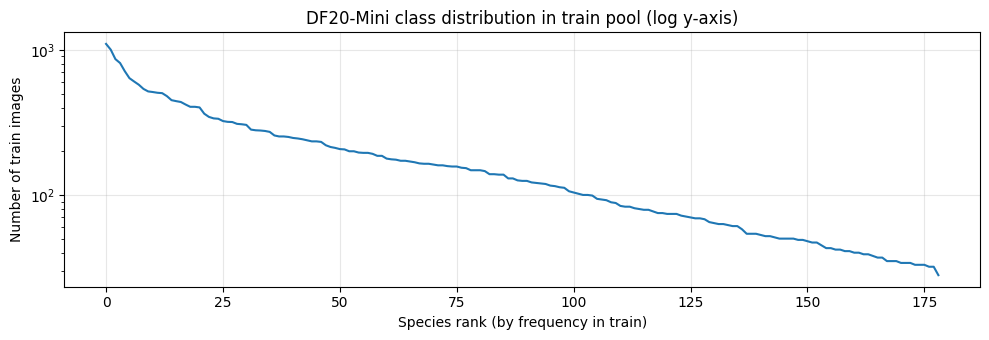

In [11]:
# Analyze the TRAIN pool specifically — this is what AL actually draws from.
species_counts = meta[meta['split']=='train']['species'].value_counts()

print("Images per species (TRAIN pool):")
print(f"  max:         {species_counts.max():>5}   ({species_counts.idxmax()})")
print(f"  median:      {int(species_counts.median()):>5}")
print(f"  min:         {species_counts.min():>5}   ({species_counts.idxmin()})")
print(f"  99th pct:    {int(species_counts.quantile(0.99)):>5}")
print(f"  1st pct:     {int(species_counts.quantile(0.01)):>5}")
print(f"\nImbalance ratio (max/min): {species_counts.max() / species_counts.min():.1f}x")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(np.arange(len(species_counts)), species_counts.values)
ax.set_xlabel('Species rank (by frequency in train)')
ax.set_ylabel('Number of train images')
ax.set_yscale('log')
ax.set_title('DF20-Mini class distribution in train pool (log y-axis)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 3 — Assign Integer Species IDs

Sorted alphabetically for stable, reproducible IDs across runs.

In [12]:
# Drop rows whose species never appears in the train pool — a classifier
# can't learn classes with zero training examples.
train_species = set(meta[meta['split']=='train']['species'])
test_only_mask = ~meta['species'].isin(train_species)
if test_only_mask.any():
    dropped = test_only_mask.sum()
    print(f"Dropping {dropped} rows belonging to species not present in train pool")
    meta = meta[~test_only_mask].reset_index(drop=True)

# Alphabetical species_id assignment, stable across runs.
unique_species = sorted(meta['species'].unique())
species_to_id = {s: i for i, s in enumerate(unique_species)}
meta['species_id'] = meta['species'].map(species_to_id)
N_CLASSES = len(unique_species)
print(f"N classes: {N_CLASSES}")
print(f"Train pool: {(meta['split']=='train').sum():,} images")
print(f"Test set:   {(meta['split']=='test').sum():,} images")

N classes: 179
Train pool: 32,724 images
Test set:   3,637 images


## Step 4 — Image Dataset

Loads image, applies CLIP preprocessing, returns tensor + row index + valid flag. Corrupt/missing files return zeros and `valid=False` so we can drop them before saving.

In [16]:
class DF20MiniDataset(Dataset):
    def __init__(self, metadata_df, image_root, transform):
        self.metadata  = metadata_df.reset_index(drop=True)
        self.root      = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, idx):
        row = self.metadata.iloc[idx]
        path = self.root / row['image_path']
        try:
            img = Image.open(path).convert('RGB')
            return self.transform(img), idx, True
        except Exception:
            return torch.zeros(3, 224, 224), idx, False

## Step 5 — Load CLIP ViT-B/32

In [14]:
model, _, preprocess = open_clip.create_model_and_transforms(
    CLIP_MODEL_NAME, pretrained=CLIP_PRETRAINED
)
model = model.to(DEVICE).eval()
for p in model.parameters():
    p.requires_grad_(False)

EMBED_DIM = model.visual.output_dim
print(f"Loaded {CLIP_MODEL_NAME} ({CLIP_PRETRAINED}) on {DEVICE}")
print(f"Embedding dim: {EMBED_DIM}")

/Users/lucilu/miniconda3/envs/mushroom-project/lib/python3.11/site-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Loaded ViT-B-32 (openai) on mps
Embedding dim: 512


## Step 6 — Extract Embeddings

5–15 minutes on M4 MPS for ~29k images. Embeddings are L2-normalized per row (makes cosine similarity equal dot product).

In [22]:
dataset = DF20MiniDataset(meta, DATA_DIR, preprocess)
loader  = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == 'cuda'),
)

embeddings = np.zeros((len(dataset), EMBED_DIM), dtype=np.float32)
valid_mask = np.zeros(len(dataset), dtype=bool)

with torch.no_grad():
    for batch_imgs, batch_idx, batch_valid in tqdm(loader, desc='Encoding'):
        batch_imgs = batch_imgs.to(DEVICE, non_blocking=True)
        feats = model.encode_image(batch_imgs)
        feats = feats / feats.norm(dim=-1, keepdim=True)
        feats = feats.cpu().numpy()

        idx = batch_idx.numpy()
        embeddings[idx] = feats
        valid_mask[idx] = batch_valid.numpy()

print(f"\nEncoded {valid_mask.sum()} / {len(dataset)} valid images")
if (~valid_mask).sum() > 0:
    print(f"Skipped {(~valid_mask).sum()} corrupt/missing files")

Encoding: 100%|██████████| 569/569 [10:46<00:00,  1.14s/it]


Encoded 36361 / 36361 valid images


## Step 7 — Filter and Save

Drop corrupt rows, reindex, save three files:

- `df20m_embeddings.npy` — the embedding matrix
- `df20m_metadata.parquet` — per-image rows (includes the split column)
- `species_info.parquet` — per-species lookup table


In [23]:
meta_clean = meta[valid_mask].reset_index(drop=True)
embed_clean = embeddings[valid_mask]
meta_clean['embedding_idx'] = np.arange(len(meta_clean))

# Sanity: every species still has at least one test sample?
test_species = set(meta_clean[meta_clean['split'] == 'test']['species'])
all_species  = set(meta_clean['species'])
no_test = all_species - test_species
if no_test:
    print(f"WARNING: {len(no_test)} species have zero test samples after corrupt-image filtering")
    print(f"  (first 5): {list(no_test)[:5]}")
    print(f"  Downstream per-class test metrics will skip these species.")

# Per-species table
species_info = (
    meta_clean.groupby('species', sort=True)
              .agg(species_id=('species_id', 'first'),
                   genus=('genus', 'first'),
                   n_images=('species', 'size'),
                   n_train=('split', lambda s: (s == 'train').sum()),
                   n_test=('split',  lambda s: (s == 'test').sum()))
              .reset_index()
              .sort_values('species_id')
)

print(f"Final dataset: {len(meta_clean):,} images, {len(species_info)} species")
print(f"Embedding memory: {embed_clean.nbytes / 1e6:.1f} MB")

Final dataset: 36,361 images, 179 species
Embedding memory: 74.5 MB


In [26]:
np.save(OUTPUT_DIR / 'df20m_embeddings.npy', embed_clean)
meta_clean.to_csv(OUTPUT_DIR / 'df20m_metadata.csv', index=False)
species_info.to_csv(OUTPUT_DIR / 'species_info.csv', index=False)

summary = {
    'clip_model':      CLIP_MODEL_NAME,
    'clip_pretrained': CLIP_PRETRAINED,
    'embedding_dim':   int(embed_clean.shape[1]),
    'n_images':        int(len(meta_clean)),
    'n_species':       int(len(species_info)),
    'n_genera':        int(meta_clean['genus'].nunique()),
    'n_train':         int((meta_clean['split'] == 'train').sum()),
    'n_test':          int((meta_clean['split'] == 'test').sum()),
    'split_source':    'official DF20-Mini train/test CSVs',
    'random_state':    RANDOM_STATE,
    'device':          str(DEVICE),
}
with open(OUTPUT_DIR / 'df20m_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(f"Saved to {OUTPUT_DIR}/")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {p.name:40s} {p.stat().st_size / 1e6:8.2f} MB")
print(f"\n{json.dumps(summary, indent=2)}")

Saved to artifacts/
  df20m_embeddings.npy                        74.47 MB
  df20m_metadata.csv                          13.07 MB
  df20m_summary.json                           0.00 MB
  species_info.csv                             0.01 MB

{
  "clip_model": "ViT-B-32",
  "clip_pretrained": "openai",
  "embedding_dim": 512,
  "n_images": 36361,
  "n_species": 179,
  "n_genera": 6,
  "n_train": 32724,
  "n_test": 3637,
  "split_source": "official DF20-Mini train/test CSVs",
  "random_state": 42,
  "device": "mps"
}


## Step 8 — Sanity Checks

Three diagnostics before committing to downstream AL experiments:

1. **Same-species cosine similarity gap** — same-species pairs should score measurably higher than random pairs.
2. **1-NN species accuracy on the held-out test set** — cheap lower bound for attainable accuracy using frozen CLIP features. Sets the bar your AL-trained classifiers should exceed.
3. **UMAP 2D projection** — visual clustering check.

If any of these look broken, don't proceed. Debug first.

In [28]:
# 1. Same vs random-pair cosine similarity
rng = np.random.RandomState(42)
n_test = min(2000, len(embed_clean))
idx = rng.choice(len(embed_clean), size=n_test, replace=False)
sub_embed   = embed_clean[idx]
sub_species = meta_clean['species'].to_numpy(dtype=object)[idx]   # <-- changed

sim = sub_embed @ sub_embed.T
same_mask = sub_species[:, None] == sub_species[None, :]
np.fill_diagonal(same_mask, False)
diff_mask = ~same_mask
np.fill_diagonal(diff_mask, False)

same_sim = sim[same_mask].mean()
diff_sim = sim[diff_mask].mean()
print(f"Cosine similarity:")
print(f"  same species:      {same_sim:.4f}")
print(f"  different species: {diff_sim:.4f}")
print(f"  gap:               {same_sim - diff_sim:.4f}")
print(f"\nGap > 0.05 → embeddings carry species signal. Near zero → investigate.")

Cosine similarity:
  same species:      0.8238
  different species: 0.7972
  gap:               0.0266

Gap > 0.05 → embeddings carry species signal. Near zero → investigate.


In [29]:
# 2. 1-NN accuracy on train/test split (uses the split column saved above)
from sklearn.neighbors import KNeighborsClassifier

train_mask = meta_clean['split'].values == 'train'
test_mask  = meta_clean['split'].values == 'test'

X_train = embed_clean[train_mask]
y_train = meta_clean['species_id'].values[train_mask]
X_test  = embed_clean[test_mask]
y_test  = meta_clean['species_id'].values[test_mask]

knn = KNeighborsClassifier(n_neighbors=1, metric='cosine', n_jobs=-1)
knn.fit(X_train, y_train)
acc = knn.score(X_test, y_test)

print(f"1-NN species accuracy on held-out test: {acc:.4f}")
print(f"  ({len(meta_clean['species'].unique())} classes, chance = {1/len(meta_clean['species'].unique()):.4f})")
print(f"\nInterpretation:")
print(f"  - Frozen CLIP + 1-NN typically scores 50-70% on fine-grained tasks like this")
print(f"  - Fine-tuned ViT in the DF20 paper reaches ~80% on full DF20")
print(f"  - Your trained AL classifier should beat 1-NN with far fewer labels than the full pool")

1-NN species accuracy on held-out test: 0.2843
  (179 classes, chance = 0.0056)

Interpretation:
  - Frozen CLIP + 1-NN typically scores 50-70% on fine-grained tasks like this
  - Fine-tuned ViT in the DF20 paper reaches ~80% on full DF20
  - Your trained AL classifier should beat 1-NN with far fewer labels than the full pool


In [30]:
# 3. Optional UMAP 2D by genus
try:
    import umap
    reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    emb_2d  = reducer.fit_transform(embed_clean[idx])

    fig, ax = plt.subplots(figsize=(8, 6))
    for g in sorted(np.unique(meta_clean['genus'].values[idx])):
        m = meta_clean['genus'].values[idx] == g
        ax.scatter(emb_2d[m, 0], emb_2d[m, 1], s=6, alpha=0.6, label=g)
    ax.set_title('CLIP embeddings — UMAP, colored by genus')
    ax.legend(markerscale=2)
    plt.tight_layout()
    plt.show()
except ImportError:
    print("umap-learn not installed; skipping.  pip install umap-learn")

umap-learn not installed; skipping.  pip install umap-learn


## Done

What gets loaded by the next notebook:

```python
embeddings   = np.load('artifacts/df20m_embeddings.npy')            # (N, 512)
metadata     = pd.read_parquet('artifacts/df20m_metadata.parquet')  # per-image
species_info = pd.read_parquet('artifacts/species_info.parquet')    # per-species

train = metadata['split'] == 'train'
test  = metadata['split'] == 'test'

X_pool, y_pool = embeddings[train], metadata['species_id'].values[train]
X_test, y_test = embeddings[test],  metadata['species_id'].values[test]
```

Notebook 2 (`02_active_learning.ipynb`) then compares AL query strategies on this fine-grained multi-class task. Write it after you've confirmed Step 9 looks healthy.
